# 02 · Inferência estatística — Aluguel São Paulo (capital)

**Entrada:** `data/interim/aluguel_sp_clean.parquet` (saída do notebook 01).

**Objetivo:** testar as hipóteses H1–H11 levantadas na EDA e separar **associação** de **efeito controlado**.
O resultado orienta o feature engineering (03) e a escolha de modelos (04).

### Princípios

1. **Com n ≈ 22 mil, quase tudo dá p < 0,05.** O que decide é o **tamanho do efeito** e o **intervalo de confiança**, não só o p-valor.
2. **Testes não paramétricos** (Kruskal-Wallis, Mann-Whitney) quando a comparação é de distribuições: o R$/m² é assimétrico e a variância muda entre grupos.
3. **Regressão OLS em `log(rent)`** para efeitos controlados. Coeficientes viram **% de efeito** via `exp(β) − 1`.
4. **Erros-padrão robustos agrupados por região** (cluster): anúncios da mesma região não são independentes.
5. **Correção para testes múltiplos** (Holm) quando uma família de testes responde à mesma pergunta.

### Roteiro
1. Setup e carga
2. Pressupostos: normalidade e homocedasticidade
3. H7 — Multicolinearidade (VIF)
4. H1 — Elasticidade área × aluguel
5. H4 — Efeito do tipo controlando a área
6. H2 — Diferença de R$/m² entre regiões
7. H9 — Distância ao centro é não linear?
8. H3, H5 — Mobília e pet (testes estratificados)
9. Modelo controlado: H3, H5, H6, H8, H10 (ingênuo × controlado)
10. H11 — Studios × R$/m² da região
11. Diagnóstico dos resíduos (inclui autocorrelação espacial)
12. Quadro-resumo das hipóteses
13. Conclusões e implicações para o 03/04

## 1. Setup e carga

In [1]:
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick
import seaborn as sns
from scipy import stats
import statsmodels.api as sm
import statsmodels.formula.api as smf
from statsmodels.stats.anova import anova_lm
from statsmodels.stats.diagnostic import het_breuschpagan
from statsmodels.stats.multitest import multipletests
from statsmodels.stats.outliers_influence import variance_inflation_factor
from sklearn.neighbors import BallTree

import warnings
warnings.filterwarnings("ignore", category=FutureWarning)

pd.options.display.float_format = "{:,.3f}".format
pd.set_option("display.max_columns", 60)
sns.set_theme(style="whitegrid", context="notebook")

COR = "#2a6f97"
CINZA = "#c0c7cf"
TIPOS = ["Apartamento", "Casa", "StudioOuKitchenette", "CasaCondominio"]
PALETA = dict(zip(TIPOS, ["#2a6f97", "#e07a1f", "#3a9d5d", "#8e5ba8"]))
ALFA = 0.05
RNG = 42


def achar_raiz(marcador: str = ".git") -> Path:
    p = Path.cwd().resolve()
    for candidato in [p, *p.parents]:
        if (candidato / marcador).exists():
            return candidato
    raise FileNotFoundError(f"Raiz do projeto ({marcador}) não encontrada a partir de {p}")


ROOT = achar_raiz()
df = pd.read_parquet(ROOT / "data/interim/aluguel_sp_clean.parquet")
print(df.shape)

(22213, 96)


In [2]:
# Variáveis auxiliares da inferência
df["log_area"] = np.log(df["area"])
df["mobiliado"] = df["isFurnished"].fillna(False).astype(int)
df["pet"] = df["am_pode_ter_animais_de_estimacao"]

# Regiões com menos de 30 anúncios viram "Outras" (efeito fixo estável)
n_reg = df["regionName"].map(df["regionName"].value_counts())
df["regiao"] = df["regionName"].where(n_reg >= 30, "Outras").astype(str)
print(f"Regiões com n >= 30: {df['regiao'].nunique() - 1}  |  anúncios em 'Outras': {(df['regiao'] == 'Outras').mean():.1%}")

# Quadro-resumo preenchido ao longo do notebook
resumo = []


def registrar(hip, pergunta, teste, estatistica, p, efeito, conclusao):
    resumo.append({"hipótese": hip, "pergunta": pergunta, "teste": teste,
                   "estatística": estatistica, "p": p, "efeito": efeito, "conclusão": conclusao})


def pct(b):
    """Coeficiente em log -> efeito percentual."""
    return np.exp(b) - 1

Regiões com n >= 30: 133  |  anúncios em 'Outras': 8.5%


## 2. Pressupostos: normalidade e homocedasticidade

Testes formais de normalidade (Shapiro, D'Agostino) **sempre rejeitam com n grande**, mesmo para desvios irrelevantes.
Por isso o diagnóstico principal é **visual** (QQ-plot); o teste fica como registro.

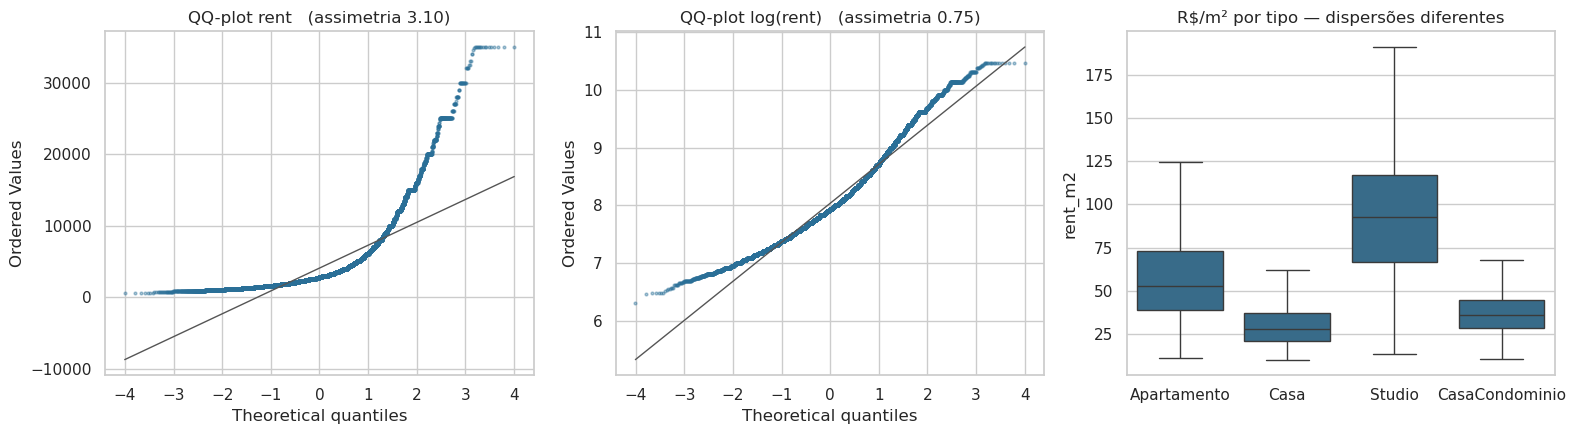

D'Agostino log(rent): K² = 1,740, p = 0.0e+00
Levene (mediana) R$/m² entre tipos: W = 621.2, p = 0.0e+00

Desvio-padrão de R$/m² por tipo:
type
Apartamento           30.400
Casa                  15.600
StudioOuKitchenette   35.800
CasaCondominio        19.900


In [3]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))
for ax, col, nome in zip(axes[:2], ["rent", "log_rent"], ["rent", "log(rent)"]):
    stats.probplot(df[col], dist="norm", plot=ax)
    ax.get_lines()[0].set(markersize=2, alpha=0.4, color=COR)
    ax.get_lines()[1].set(color="#555", lw=1)
    k2, p = stats.normaltest(df[col])
    ax.set_title(f"QQ-plot {nome}   (assimetria {df[col].skew():.2f})")

sns.boxplot(data=df, x="type", y="rent_m2", order=TIPOS, ax=axes[2], color=COR, showfliers=False)
axes[2].set_xticks(range(len(TIPOS)), [t.replace("OuKitchenette", "") for t in TIPOS])
axes[2].set_xlabel("")
axes[2].set_title("R$/m² por tipo — dispersões diferentes")
plt.tight_layout()
plt.show()

k2, p_norm = stats.normaltest(df["log_rent"])
lev, p_lev = stats.levene(*[g["rent_m2"].values for _, g in df.groupby("type")], center="median")
print(f"D'Agostino log(rent): K² = {k2:,.0f}, p = {p_norm:.1e}")
print(f"Levene (mediana) R$/m² entre tipos: W = {lev:,.1f}, p = {p_lev:.1e}")
print("\nDesvio-padrão de R$/m² por tipo:")
print(df.groupby("type")["rent_m2"].std().reindex(TIPOS).round(1).to_string())

**Leitura:** `log(rent)` fica bem mais próximo da normal que `rent` (desvios só nas caudas), o que sustenta OLS em log.
A variância difere entre grupos (Levene rejeita), então:
- comparações de grupos usam **Kruskal-Wallis / Mann-Whitney**;
- regressões usam **erros-padrão robustos** (HC3 ou cluster por região).

## 3. H7 — Multicolinearidade (VIF)

VIF > 5 indica colinearidade relevante; > 10, grave. Afeta a **interpretação** de coeficientes lineares, não a capacidade preditiva de árvores.

In [4]:
def tabela_vif(cols):
    X = sm.add_constant(df[cols].astype(float))
    return (pd.Series([variance_inflation_factor(X.values, i) for i in range(1, X.shape[1])],
                      index=cols, name="VIF").sort_values(ascending=False))


COLS_PLANTA = ["log_area", "bedrooms", "bathrooms", "suites", "parkingSpaces"]
vif_completo = tabela_vif(COLS_PLANTA)
vif_reduzido = tabela_vif(["log_area", "suites", "parkingSpaces"])

print("VIF — todas as variáveis de planta")
print(vif_completo.round(2).to_string())
print("\nVIF — sem bedrooms e bathrooms")
print(vif_reduzido.round(2).to_string())

registrar("H7", "Variáveis de planta são colineares?", "VIF", f"VIF máx = {vif_completo.max():.1f}", np.nan,
          f"{vif_completo.idxmax()} = {vif_completo.max():.1f}",
          "Colinearidade moderada" if vif_completo.max() < 10 else "Colinearidade grave")

VIF — todas as variáveis de planta
bathrooms       5.110
log_area        4.450
bedrooms        3.170
parkingSpaces   2.700
suites          2.660

VIF — sem bedrooms e bathrooms
log_area        2.730
parkingSpaces   2.640
suites          1.660


**Decisão para os modelos lineares deste notebook:** manter `log_area`, `bathrooms`, `suites` e `parkingSpaces`, e retirar `bedrooms` (redundante com área).
Nos modelos de árvore do 04 todas podem entrar.

## 4. H1 — Elasticidade área × aluguel

Modelo: `log(rent) = α + β · log(area)`. β é a elasticidade: +1% de área → +β% de aluguel.

- H0: β = 1 (aluguel proporcional à área)
- H1: β < 1 (o m² extra vale menos)

Também estimamos β **por tipo** (interação) e **controlando a região**, porque imóveis grandes ficam mais longe do centro.

In [5]:
CLUSTER = {"cov_type": "cluster", "cov_kwds": {"groups": pd.factorize(df["regiao"])[0]}}

m_simples = smf.ols("log_rent ~ log_area", data=df).fit(**CLUSTER)
m_regiao = smf.ols("log_rent ~ log_area + C(regiao)", data=df).fit(**CLUSTER)
m_tipo = smf.ols("log_rent ~ log_area:C(type) + C(type) + C(regiao)", data=df).fit(**CLUSTER)

linhas = []
for nome, m, termo in [("simples", m_simples, "log_area"), ("+ efeito fixo de região", m_regiao, "log_area")]:
    b, (lo, hi) = m.params[termo], m.conf_int().loc[termo]
    t = m.t_test(f"{termo} = 1")
    linhas.append({"modelo": nome, "β": b, "IC95 inf": lo, "IC95 sup": hi,
                   "p (H0: β=1)": float(t.pvalue), "R²": m.rsquared})
for tipo in TIPOS:
    termo = f"log_area:C(type)[{tipo}]"
    b, (lo, hi) = m_tipo.params[termo], m_tipo.conf_int().loc[termo]
    linhas.append({"modelo": f"{tipo} (+ região)", "β": b, "IC95 inf": lo, "IC95 sup": hi,
                   "p (H0: β=1)": float(m_tipo.t_test(f"{termo} = 1").pvalue), "R²": m_tipo.rsquared})
elast = pd.DataFrame(linhas).set_index("modelo")
elast

,β,IC95 inf,IC95 sup,p (H0: β=1),R²
modelo,,,,,
simples,0.611,0.575,0.648,0.000,0.514
+ efeito fixo de região,0.645,0.615,0.675,0.000,0.754
Apartamento (+ região),0.707,0.671,0.743,0.000,0.771
Casa (+ região),0.780,0.740,0.820,0.000,0.771
StudioOuKitchenette (+ região),0.441,0.358,0.523,0.000,0.771
CasaCondominio (+ região),0.758,0.670,0.847,0.000,0.771


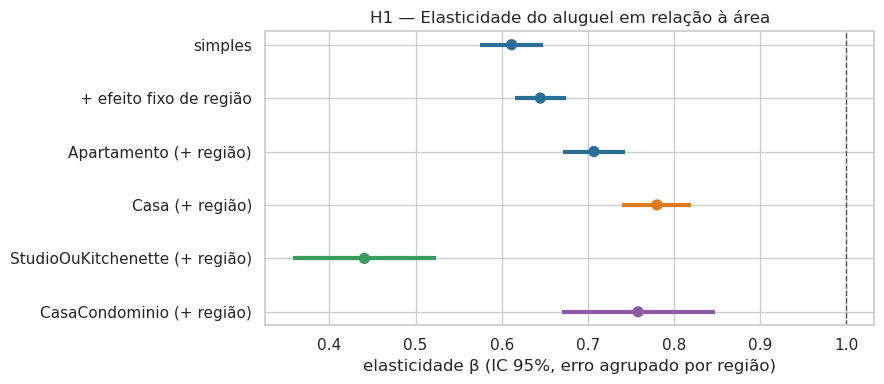

In [6]:
fig, ax = plt.subplots(figsize=(9, 4))
y = np.arange(len(elast))[::-1]
cores = [COR, COR] + [PALETA[t] for t in TIPOS]
ax.hlines(y, elast["IC95 inf"], elast["IC95 sup"], color=cores, lw=3)
ax.scatter(elast["β"], y, color=cores, s=50, zorder=3)
ax.axvline(1, color="#555", ls="--", lw=1)
ax.annotate("β = 1 (proporcional)", (1, y.max() + 0.4), ha="right", fontsize=9, color="#555")
ax.set_yticks(y, elast.index)
ax.set_xlabel("elasticidade β (IC 95%, erro agrupado por região)")
ax.set_title("H1 — Elasticidade do aluguel em relação à área")
plt.tight_layout()
plt.show()

b = elast.loc["+ efeito fixo de região"]
registrar("H1", "Aluguel cresce menos que proporcionalmente à área?", "OLS log-log + FE região, t-test β=1",
          f"β = {b['β']:.2f} [{b['IC95 inf']:.2f}; {b['IC95 sup']:.2f}]", b["p (H0: β=1)"],
          f"+10% área → +{(1.1 ** b['β'] - 1):.1%} aluguel",
          "Rejeita H0: elasticidade < 1" if b["IC95 sup"] < 1 and b["p (H0: β=1)"] < ALFA else "Não rejeita H0")

## 5. H4 — Efeito do tipo de imóvel controlando a área

Na EDA, o studio tem o maior R$/m². Mas studios são pequenos, e m² de imóvel pequeno é mais caro (H1).
Pergunta: **para a mesma área e a mesma região**, o tipo ainda muda o aluguel? Referência: Apartamento.

In [7]:
f_tipo = "log_rent ~ log_area + C(type, Treatment('Apartamento')) + C(regiao)"
m_h4 = smf.ols(f_tipo, data=df).fit(**CLUSTER)
m_h4_sem = smf.ols("log_rent ~ log_area + C(regiao)", data=df).fit(**CLUSTER)

termos = [t for t in m_h4.params.index if t.startswith("C(type")]
h4 = pd.DataFrame({
    "tipo": [t.split("[T.")[1].rstrip("]") for t in termos],
    "efeito %": pct(m_h4.params[termos]).values,
    "IC95 inf": pct(m_h4.conf_int().loc[termos, 0]).values,
    "IC95 sup": pct(m_h4.conf_int().loc[termos, 1]).values,
    "p": m_h4.pvalues[termos].values,
}).set_index("tipo")

# Wald conjunto: todos os coeficientes de tipo = 0
wald = m_h4.wald_test(" , ".join(f"{t} = 0" for t in termos), scalar=True)
print(f"Wald conjunto (tipo = 0): χ² = {wald.statistic:,.1f} ({len(termos)} gl), p = {wald.pvalue:.1e}")
print(f"R² sem tipo: {m_h4_sem.rsquared:.3f}  |  com tipo: {m_h4.rsquared:.3f}")
h4.assign(**{c: h4[c].map("{:+.1%}".format) for c in ["efeito %", "IC95 inf", "IC95 sup"]})

Wald conjunto (tipo = 0): χ² = 302.4 (3 gl), p = 3.0e-65
R² sem tipo: 0.754  |  com tipo: 0.768


,efeito %,IC95 inf,IC95 sup,p
tipo,,,,
Casa,-22.0%,-24.1%,-19.8%,0.000
CasaCondominio,-8.2%,-11.8%,-4.5%,0.000
StudioOuKitchenette,+8.3%,+5.2%,+11.5%,0.000


In [8]:
registrar("H4", "Tipo muda o aluguel na mesma área e região?", "OLS + FE região, Wald conjunto",
          f"χ² = {wald.statistic:,.1f}", wald.pvalue,
          "; ".join(f"{t.replace('OuKitchenette', '')} {v:+.0%}" for t, v in h4["efeito %"].items()),
          "Rejeita H0: tipo tem efeito próprio" if wald.pvalue < ALFA else "Não rejeita H0")

## 6. H2 — O R$/m² difere entre regiões?

- **Global:** Kruskal-Wallis nas 133 regiões com n ≥ 30, com tamanho de efeito **ε²** (0,01 pequeno · 0,06 médio · 0,14 grande).
- **Post-hoc:** Mann-Whitney par a par entre as 10 regiões com mais anúncios, p ajustado por Holm (45 comparações).

In [9]:
grupos = [g["rent_m2"].values for r, g in df[df["regiao"] != "Outras"].groupby("regiao")]
H, p_kw = stats.kruskal(*grupos)
n_kw = sum(len(g) for g in grupos)
eps2 = H / (n_kw - 1)
print(f"Kruskal-Wallis: H = {H:,.0f}, p = {p_kw:.1e}, ε² = {eps2:.3f}  ({len(grupos)} regiões, n = {n_kw:,})")

registrar("H2", "R$/m² difere entre regiões?", "Kruskal-Wallis", f"H = {H:,.0f}", p_kw,
          f"ε² = {eps2:.2f} ({'grande' if eps2 >= .14 else 'médio' if eps2 >= .06 else 'pequeno'})",
          "Rejeita H0: regiões diferem" if p_kw < ALFA else "Não rejeita H0")

Kruskal-Wallis: H = 8,532, p = 0.0e+00, ε² = 0.420  (133 regiões, n = 20,323)


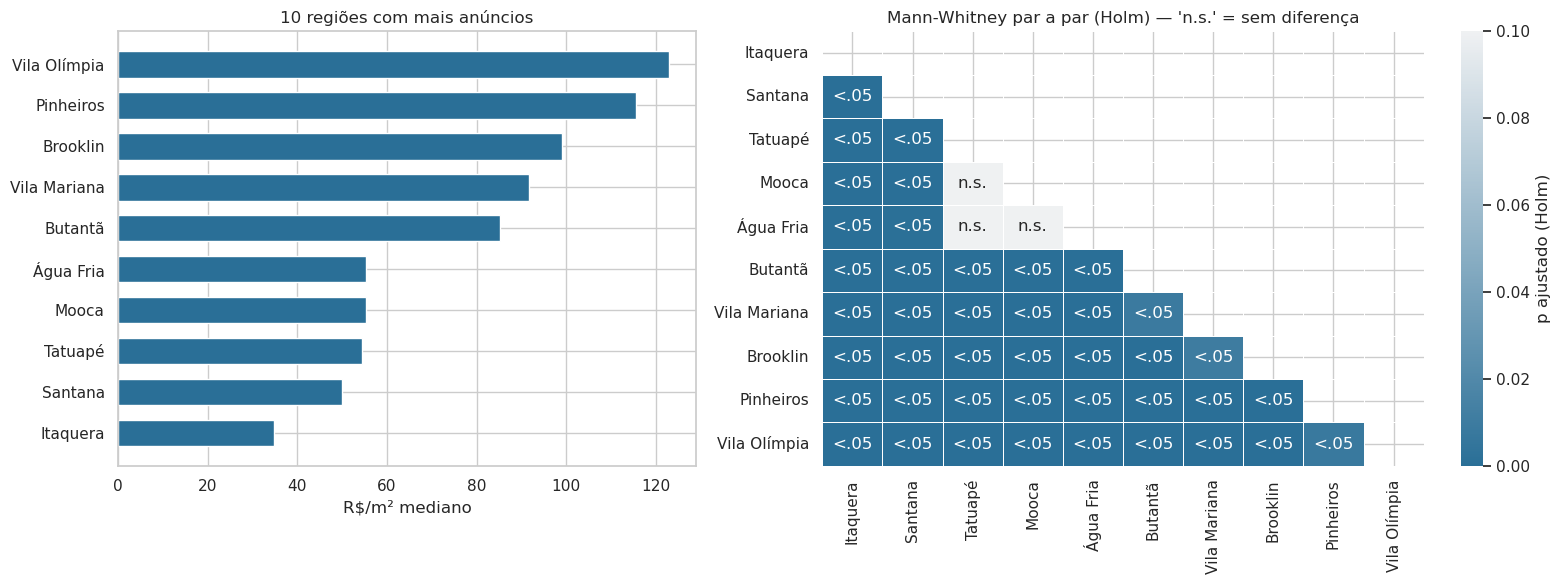

42 de 45 pares diferem após Holm.
Pares SEM diferença significativa:
  Tatuapé × Mooca  (p = 1.00)
  Tatuapé × Água Fria  (p = 1.00)
  Mooca × Água Fria  (p = 1.00)


In [10]:
top10 = df["regiao"].value_counts().drop("Outras", errors="ignore").head(10).index
med = df[df["regiao"].isin(top10)].groupby("regiao")["rent_m2"].median().sort_values()
ordem = med.index.tolist()

pares, pvals = [], []
for i, a in enumerate(ordem):
    for b in ordem[i + 1:]:
        pares.append((a, b))
        pvals.append(stats.mannwhitneyu(df.loc[df["regiao"] == a, "rent_m2"],
                                        df.loc[df["regiao"] == b, "rent_m2"]).pvalue)
rej, p_holm, _, _ = multipletests(pvals, alpha=ALFA, method="holm")

mat = pd.DataFrame(np.nan, index=ordem, columns=ordem)
for (a, b), p in zip(pares, p_holm):
    mat.loc[a, b] = mat.loc[b, a] = p

fig, axes = plt.subplots(1, 2, figsize=(16, 6), gridspec_kw={"width_ratios": [1, 1.3]})
axes[0].barh(med.index, med.values, color=COR, height=0.65)
axes[0].set_xlabel("R$/m² mediano")
axes[0].set_title("10 regiões com mais anúncios")

mask = np.triu(np.ones_like(mat, dtype=bool))
sns.heatmap(mat.where(~mask), annot=mat.where(~mask).map(lambda p: "" if pd.isna(p) else ("n.s." if p >= ALFA else "<.05")),
            fmt="", cmap=sns.light_palette(COR, reverse=True, as_cmap=True), vmin=0, vmax=0.1,
            cbar_kws={"label": "p ajustado (Holm)"}, ax=axes[1], linewidths=0.5, linecolor="white")
axes[1].set_title("Mann-Whitney par a par (Holm) — 'n.s.' = sem diferença")
plt.tight_layout()
plt.show()

print(f"{rej.sum()} de {len(rej)} pares diferem após Holm.")
print("Pares SEM diferença significativa:")
for (a, b), r, p in zip(pares, rej, p_holm):
    if not r:
        print(f"  {a} × {b}  (p = {p:.2f})")

> Regiões vizinhas e de perfil parecido podem não diferir entre si. Isso sugere que, para o modelo, **agrupar regiões semelhantes** (clusters de preço) ou usar target encoding suavizado perde pouca informação e reduz cardinalidade.

## 7. H9 — A distância ao centro tem efeito não linear?

Na EDA, o R$/m² sobe até ~5 km da Sé e depois cai. Comparamos dois modelos aninhados (controlando área e tipo, **sem** efeito fixo de região — senão a região absorve a distância):

- linear: `... + dist_centro_km`
- spline cúbica (5 graus de liberdade): `... + bs(dist_centro_km, df=5)`

Teste F para os termos extras + AIC.

    df_resid       ssr  df_diff  ss_diff       F  Pr(>F)
0 22,207.000 3,687.520    0.000      NaN     NaN     NaN
1 22,203.000 3,543.236    4.000  144.285 226.033   0.000

AIC linear: 23,161  |  AIC spline: 22,283
R² linear : 0.650  |  R² spline : 0.664


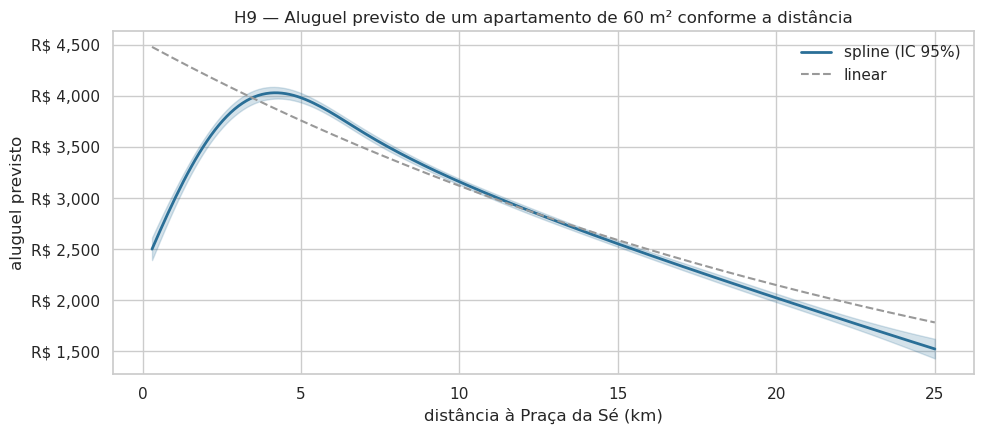

In [11]:
base = "log_rent ~ log_area + C(type)"
m_lin = smf.ols(f"{base} + dist_centro_km", data=df).fit()
m_spl = smf.ols(f"{base} + bs(dist_centro_km, df=5)", data=df).fit()

f_test = anova_lm(m_lin, m_spl)
print(f_test)
print(f"\nAIC linear: {m_lin.aic:,.0f}  |  AIC spline: {m_spl.aic:,.0f}")
print(f"R² linear : {m_lin.rsquared:.3f}  |  R² spline : {m_spl.rsquared:.3f}")

# Curva parcial: apartamento de 60 m², variando a distância
grade = pd.DataFrame({"dist_centro_km": np.linspace(0.3, 25, 200), "log_area": np.log(60), "type": "Apartamento"})
pred_spl = m_spl.get_prediction(grade).summary_frame()
pred_lin = m_lin.predict(grade)

fig, ax = plt.subplots(figsize=(10, 4.5))
ax.fill_between(grade["dist_centro_km"], np.exp(pred_spl["mean_ci_lower"]), np.exp(pred_spl["mean_ci_upper"]),
                color=COR, alpha=0.2)
ax.plot(grade["dist_centro_km"], np.exp(pred_spl["mean"]), color=COR, lw=2, label="spline (IC 95%)")
ax.plot(grade["dist_centro_km"], np.exp(pred_lin), color="#999", lw=1.5, ls="--", label="linear")
ax.yaxis.set_major_formatter(mtick.StrMethodFormatter("R$ {x:,.0f}"))
ax.set_xlabel("distância à Praça da Sé (km)")
ax.set_ylabel("aluguel previsto")
ax.set_title("H9 — Aluguel previsto de um apartamento de 60 m² conforme a distância")
ax.legend(frameon=False)
plt.tight_layout()
plt.show()

pico = grade["dist_centro_km"].iloc[pred_spl["mean"].values.argmax()]
F, p_f = f_test["F"].iloc[1], f_test["Pr(>F)"].iloc[1]
registrar("H9", "Efeito da distância ao centro é não linear?", "F aninhado linear × spline",
          f"F = {F:,.1f}", p_f, f"pico em ~{pico:.1f} km; ΔAIC = {m_lin.aic - m_spl.aic:,.0f}",
          "Rejeita H0: não linear" if p_f < ALFA else "Não rejeita H0")

## 8. H3, H5 — Mobília e pet: testes estratificados por tipo

Antes da regressão, a versão não paramétrica: Mann-Whitney **dentro de cada tipo** (8 testes, Holm), com tamanho de efeito **rank-biserial r**
(probabilidade de um anúncio "com" ter R$/m² maior que um "sem", reescalada para −1…1; |r| 0,1 pequeno · 0,3 médio · 0,5 grande).

In [12]:
linhas = []
for col, nome in [("mobiliado", "Mobiliado"), ("pet", "Aceita pet")]:
    for tipo in TIPOS:
        s = df[df["type"] == tipo]
        com, sem = s.loc[s[col] == 1, "rent_m2"], s.loc[s[col] == 0, "rent_m2"]
        if min(len(com), len(sem)) < 30:
            continue
        U, p = stats.mannwhitneyu(com, sem)
        linhas.append({"item": nome, "tipo": tipo, "n com": len(com), "n sem": len(sem),
                       "lift mediana": com.median() / sem.median() - 1,
                       "r rank-biserial": 2 * U / (len(com) * len(sem)) - 1, "p": p})
mw = pd.DataFrame(linhas)
mw["p Holm"] = multipletests(mw["p"], method="holm")[1]
mw["significativo"] = mw["p Holm"] < ALFA
mw.assign(**{"lift mediana": mw["lift mediana"].map("{:+.1%}".format)})

,item,tipo,n com,n sem,lift mediana,r rank-biserial,p,p Holm,significativo
0,Mobiliado,Apartamento,4045,9463,+56.9%,0.515,0.000,0.000,True
1,Mobiliado,Casa,812,4200,+17.2%,0.219,0.000,0.000,True
2,Mobiliado,StudioOuKitchenette,1888,1452,+48.8%,0.536,0.000,0.000,True
3,Mobiliado,CasaCondominio,50,303,+5.4%,0.093,0.290,0.581,False
4,Aceita pet,Apartamento,10439,3069,-3.1%,-0.049,0.000,0.000,True
5,Aceita pet,Casa,3579,1433,+4.3%,0.039,0.030,0.120,False
6,Aceita pet,StudioOuKitchenette,2094,1246,+3.1%,0.041,0.049,0.148,False
7,Aceita pet,CasaCondominio,263,90,+1.2%,0.035,0.623,0.623,False


Esses efeitos ainda misturam localização: mobiliados e prédios com piscina se concentram nas regiões caras.
A regressão da próxima seção separa isso.

## 9. Modelo controlado — H3, H5, H6, H8, H10

Estimamos o efeito de cada atributo em **três níveis de controle** e vemos quanto ele encolhe:

| Nível | Fórmula |
|---|---|
| **Ingênuo** | `log_rent ~ item` |
| **+ planta** | `+ log_area + tipo + banheiros + suítes + vagas` |
| **+ planta + região** | `+ efeito fixo de região` (compara imóveis da mesma região) |

Todos com erro-padrão agrupado por região. Itens: mobiliado, pet, piscina, academia, perto de metrô/trem, varanda, ar-condicionado, vista livre, quintal.

O **modelo completo** (todos os itens juntos + planta + região) é o modelo econométrico de referência deste notebook.

In [13]:
ITENS = {
    "mobiliado": "Mobiliado",
    "pet": "Aceita pet",
    "inst_piscina": "Piscina",
    "inst_academia": "Academia",
    "inst_perto_de_metro_ou_trem": "Perto de metrô/trem",
    "am_varanda": "Varanda",
    "am_ar_condicionado": "Ar-condicionado",
    "am_vista_livre": "Vista livre",
    "am_quintal": "Quintal",
}
PLANTA = "log_area + C(type, Treatment('Apartamento')) + bathrooms + suites + parkingSpaces"
niveis = {
    "ingênuo": "log_rent ~ {item}",
    "+ planta": f"log_rent ~ {{item}} + {PLANTA}",
    "+ planta + região": f"log_rent ~ {{item}} + {PLANTA} + C(regiao)",
}

linhas = []
for item, nome in ITENS.items():
    for nivel, f in niveis.items():
        m = smf.ols(f.format(item=item), data=df).fit(**CLUSTER)
        b, (lo, hi) = m.params[item], m.conf_int().loc[item]
        linhas.append({"item": nome, "nível": nivel, "efeito": pct(b), "lo": pct(lo), "hi": pct(hi), "p": m.pvalues[item]})
cascata = pd.DataFrame(linhas)

piv = cascata.pivot(index="item", columns="nível", values="efeito")[list(niveis)]
piv.map("{:+.1%}".format)

nível,ingênuo,+ planta,+ planta + região
item,,,
Academia,+9.2%,+33.4%,+18.9%
Aceita pet,+20.1%,+2.5%,+1.1%
Ar-condicionado,+80.5%,+56.3%,+26.8%
Mobiliado,+41.8%,+42.0%,+20.8%
Perto de metrô/trem,+10.5%,+26.9%,+10.9%
Piscina,+40.9%,+34.2%,+18.5%
Quintal,+86.2%,+7.9%,+4.4%
Varanda,+59.4%,+23.4%,+13.2%
Vista livre,+30.6%,+10.9%,+5.4%


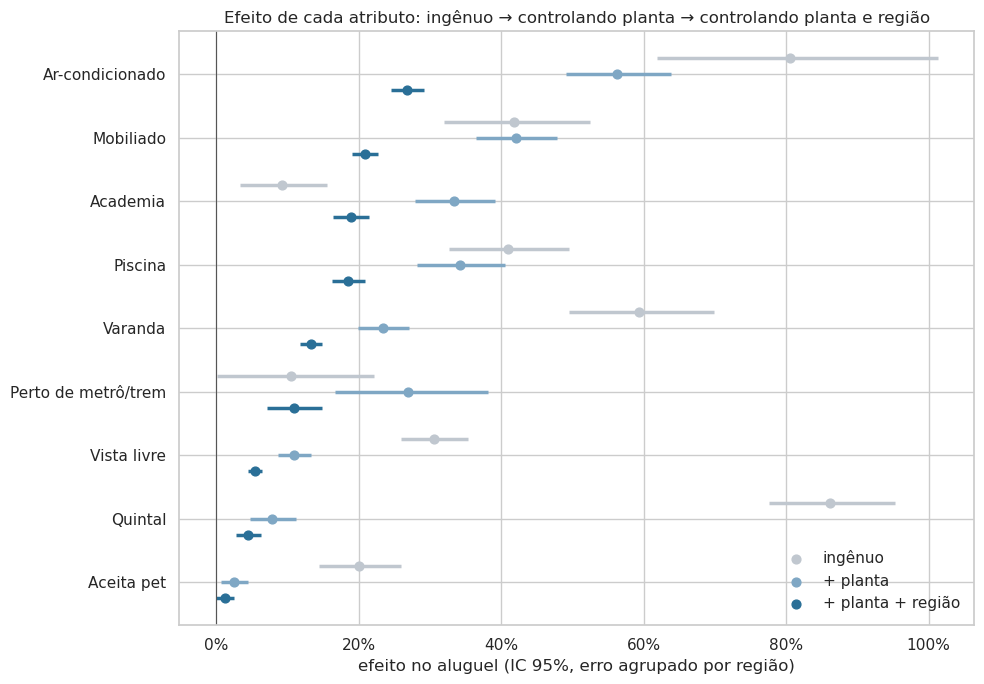

In [14]:
ordem_itens = piv.sort_values("+ planta + região").index
cores_nivel = {"ingênuo": "#c0c7cf", "+ planta": "#7fa7c4", "+ planta + região": COR}
offset = {"ingênuo": 0.25, "+ planta": 0, "+ planta + região": -0.25}

fig, ax = plt.subplots(figsize=(10, 7))
for nivel in niveis:
    sub = cascata[cascata["nível"] == nivel].set_index("item").reindex(ordem_itens)
    y = np.arange(len(sub)) + offset[nivel]
    ax.hlines(y, sub["lo"], sub["hi"], color=cores_nivel[nivel], lw=2.5)
    ax.scatter(sub["efeito"], y, color=cores_nivel[nivel], s=40, zorder=3, label=nivel)
ax.axvline(0, color="#555", lw=0.8)
ax.set_yticks(np.arange(len(ordem_itens)), ordem_itens)
ax.xaxis.set_major_formatter(mtick.PercentFormatter(1))
ax.set_xlabel("efeito no aluguel (IC 95%, erro agrupado por região)")
ax.set_title("Efeito de cada atributo: ingênuo → controlando planta → controlando planta e região")
ax.legend(frameon=False, loc="lower right")
plt.tight_layout()
plt.show()

In [15]:
f_completo = f"log_rent ~ {PLANTA} + " + " + ".join(ITENS) + " + C(regiao)"
m_completo = smf.ols(f_completo, data=df).fit(**CLUSTER)

coef = pd.DataFrame({
    "β": m_completo.params, "efeito %": pct(m_completo.params),
    "IC95 inf %": pct(m_completo.conf_int()[0]), "IC95 sup %": pct(m_completo.conf_int()[1]),
    "p": m_completo.pvalues,
})
coef = coef[~coef.index.str.startswith(("C(regiao)", "Intercept"))]
print(f"R² = {m_completo.rsquared:.3f}  |  R² ajustado = {m_completo.rsquared_adj:.3f}  |  n = {int(m_completo.nobs):,}")
coef.assign(**{c: coef[c].map("{:+.1%}".format) for c in ["efeito %", "IC95 inf %", "IC95 sup %"]})

R² = 0.834  |  R² ajustado = 0.832  |  n = 22,213


,β,efeito %,IC95 inf %,IC95 sup %,p
"C(type, Treatment('Apartamento'))[T.Casa]",-0.107,-10.1%,-12.7%,-7.5%,0.000
"C(type, Treatment('Apartamento'))[T.CasaCondominio]",-0.019,-1.8%,-5.5%,+1.9%,0.335
"C(type, Treatment('Apartamento'))[T.StudioOuKitchenette]",-0.037,-3.6%,-5.4%,-1.8%,0.000
log_area,0.491,+63.3%,+60.2%,+66.6%,0.000
bathrooms,0.068,+7.0%,+5.7%,+8.3%,0.000
suites,0.051,+5.2%,+3.9%,+6.5%,0.000
parkingSpaces,0.053,+5.5%,+4.8%,+6.2%,0.000
mobiliado,0.133,+14.3%,+12.6%,+15.9%,0.000
pet,0.010,+1.0%,-0.1%,+2.2%,0.066
inst_piscina,0.076,+7.9%,+6.2%,+9.5%,0.000


In [16]:
def concluir(item, hip, pergunta):
    """Efeito no modelo completo (todos os itens + planta + FE região) vs. ingênuo."""
    ing = cascata[(cascata["item"] == ITENS[item]) & (cascata["nível"] == "ingênuo")].iloc[0]
    b, (lo, hi), p = m_completo.params[item], m_completo.conf_int().loc[item], m_completo.pvalues[item]
    sig, relevante = p < ALFA, abs(pct(b)) >= 0.02
    concl = ("Efeito controlado relevante" if sig and relevante
             else "Significativo, mas efeito < 2%" if sig else "Sem efeito controlado")
    registrar(hip, pergunta, "OLS modelo completo + FE região (cluster)",
              f"{pct(b):+.1%} [{pct(lo):+.1%}; {pct(hi):+.1%}]", p,
              f"ingênuo {ing['efeito']:+.0%} → controlado {pct(b):+.1%}", concl)


concluir("mobiliado", "H3", "Mobiliado aumenta o aluguel (mesma planta e região)?")
concluir("pet", "H5", "Aceitar pet altera o aluguel?")
concluir("inst_piscina", "H6", "Piscina mantém efeito após controles?")
concluir("inst_perto_de_metro_ou_trem", "H8", "Perto de metrô/trem aumenta o aluguel?")

> **Cascata × modelo completo.** Na cascata cada item entra sozinho; no modelo completo, todos juntos.
> Itens que andam juntos dividem o efeito: mobiliado cai de ~+21% (sozinho) para ~+14% quando ar-condicionado entra, porque os dois andam juntos: 50% dos mobiliados têm ar-condicionado, contra 10% dos não mobiliados.
> As conclusões do quadro-resumo usam o **modelo completo**.

### H10 — O efeito da mobília depende do tipo?

Interação `mobiliado × tipo` no modelo com planta e região. Se a interação for significativa, o modelo precisa permitir efeitos diferentes por tipo (árvores fazem isso naturalmente).

In [17]:
m_h10 = smf.ols(f"log_rent ~ mobiliado * C(type, Treatment('Apartamento')) + log_area + bathrooms + suites + parkingSpaces + C(regiao)",
                data=df).fit(**CLUSTER)
inter = [t for t in m_h10.params.index if t.startswith("mobiliado:")]
w10 = m_h10.wald_test(" , ".join(f"{t} = 0" for t in inter), scalar=True)

base_ap = m_h10.params["mobiliado"]
efeitos_tipo = {"Apartamento": pct(base_ap)}
for t in inter:
    tipo = t.split("[T.")[1].rstrip("]")
    efeitos_tipo[tipo] = pct(base_ap + m_h10.params[t])
efeitos_tipo = pd.Series(efeitos_tipo).reindex(TIPOS)

print(f"Wald (interações mobiliado × tipo = 0): χ² = {w10.statistic:.1f} ({len(inter)} gl), p = {w10.pvalue:.1e}")
print("Efeito de mobiliado por tipo (mesma planta e região):")
print(efeitos_tipo.map("{:+.1%}".format).to_string())

registrar("H10", "Efeito da mobília depende do tipo?", "OLS com interação, Wald", f"χ² = {w10.statistic:.1f}", w10.pvalue,
          "; ".join(f"{t.replace('OuKitchenette', '')} {v:+.0%}" for t, v in efeitos_tipo.items()),
          "Rejeita H0: efeito varia por tipo" if w10.pvalue < ALFA else "Não rejeita H0: efeito parecido entre tipos")

Wald (interações mobiliado × tipo = 0): χ² = 9.6 (3 gl), p = 2.2e-02
Efeito de mobiliado por tipo (mesma planta e região):
Apartamento            +21.8%
Casa                   +15.2%
StudioOuKitchenette    +23.1%
CasaCondominio         +12.2%


## 10. H11 — A proporção de studios acompanha o R$/m² da região?

Unidade de análise: região (n ≥ 30). Spearman + regressão ponderada pelo número de anúncios (WLS), para que regiões pequenas não dominem.

> Para não ser circular, o R$/m² da região é calculado **só com apartamentos e casas** (sem os próprios studios, que já têm R$/m² alto).

In [18]:
nao_studio = df[df["type"] != "StudioOuKitchenette"]
reg = (
    df[df["regiao"] != "Outras"].groupby("regiao")
    .agg(n=("id", "size"), pct_studio=("type", lambda s: (s == "StudioOuKitchenette").mean()),
         dist=("dist_centro_km", "median"))
    .join(nao_studio.groupby("regiao")["rent_m2"].median().rename("rent_m2_sem_studio"))
    .dropna()
)
rho, p_rho = stats.spearmanr(reg["rent_m2_sem_studio"], reg["pct_studio"])
wls = smf.wls("pct_studio ~ rent_m2_sem_studio + dist", data=reg, weights=reg["n"]).fit(cov_type="HC3")
print(f"Spearman: ρ = {rho:.2f}, p = {p_rho:.1e}  ({len(reg)} regiões)")
print(wls.summary().tables[1])

b10 = wls.params["rent_m2_sem_studio"] * 10
registrar("H11", "Regiões caras têm mais studios?", "Spearman + WLS (controle: distância)", f"ρ = {rho:.2f}", p_rho,
          f"+10 R$/m² na região → {b10 * 100:+.1f} p.p. de studios",
          "Rejeita H0: associação positiva" if p_rho < ALFA and rho > 0 else "Não rejeita H0")

Spearman: ρ = 0.74, p = 2.7e-24  (133 regiões)
                         coef    std err          z      P>|z|      [0.025      0.975]
--------------------------------------------------------------------------------------
Intercept             -0.0009      0.063     -0.014      0.989      -0.124       0.122
rent_m2_sem_studio     0.0045      0.001      5.687      0.000       0.003       0.006
dist                  -0.0091      0.003     -2.835      0.005      -0.015      -0.003


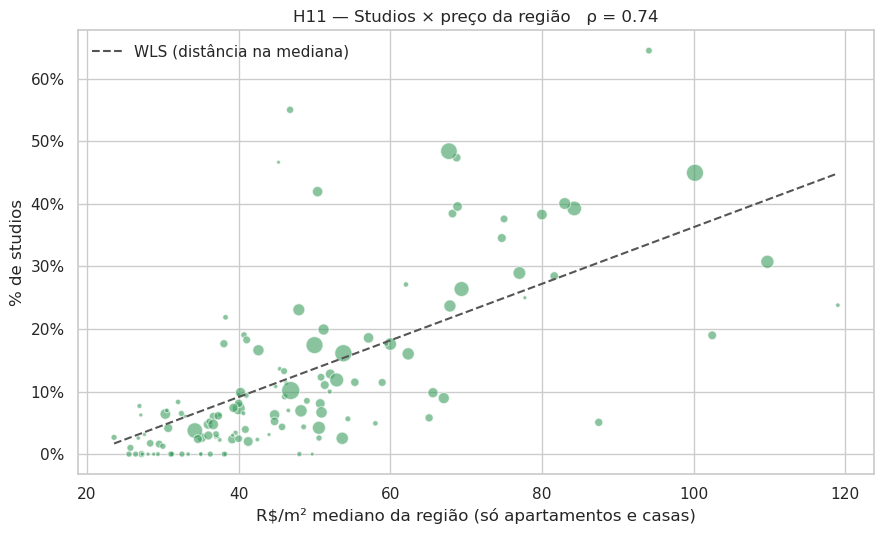

In [19]:
fig, ax = plt.subplots(figsize=(9, 5.5))
ax.scatter(reg["rent_m2_sem_studio"], reg["pct_studio"], s=reg["n"] / 4, color=PALETA["StudioOuKitchenette"],
           alpha=0.6, edgecolor="white", linewidth=0.8)
x = np.linspace(reg["rent_m2_sem_studio"].min(), reg["rent_m2_sem_studio"].max(), 50)
y = wls.params["Intercept"] + wls.params["rent_m2_sem_studio"] * x + wls.params["dist"] * reg["dist"].median()
ax.plot(x, y, color="#555", lw=1.5, ls="--", label="WLS (distância na mediana)")
ax.yaxis.set_major_formatter(mtick.PercentFormatter(1))
ax.set_xlabel("R$/m² mediano da região (só apartamentos e casas)")
ax.set_ylabel("% de studios")
ax.set_title(f"H11 — Studios × preço da região   ρ = {rho:.2f}")
ax.legend(frameon=False)
plt.tight_layout()
plt.show()

## 11. Diagnóstico dos resíduos do modelo completo

1. Resíduo × ajustado e QQ-plot.
2. Breusch-Pagan (heterocedasticidade) — justifica os erros robustos.
3. **Autocorrelação espacial**: correlação entre o resíduo de um anúncio e a média dos resíduos dos 10 vizinhos mais próximos.
   Se for alta, há informação de localização que o efeito fixo de região não capturou → features de vizinhança (03) e validação espacial (04).

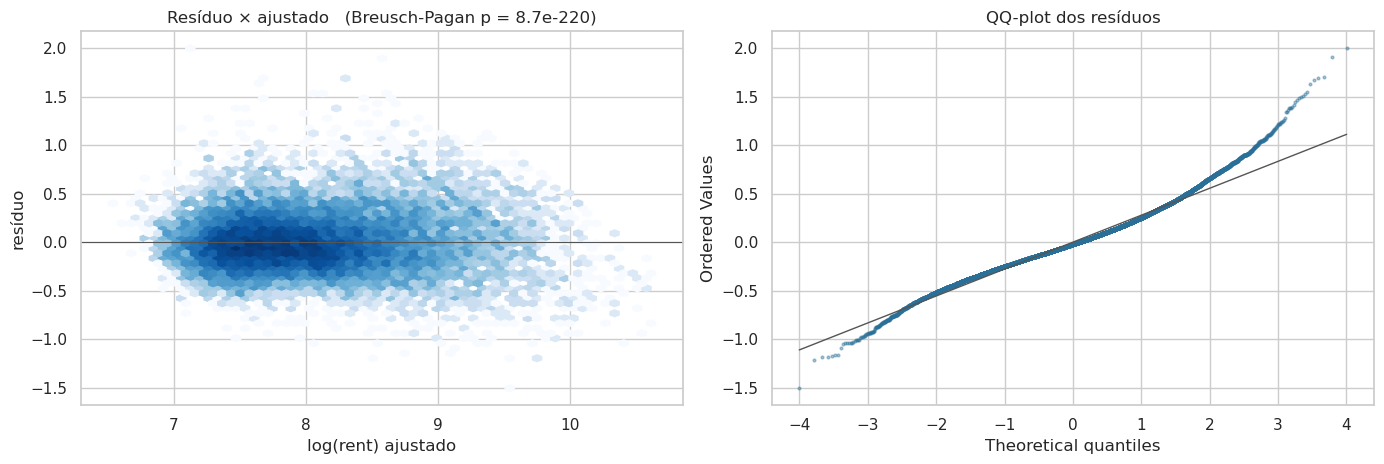

Desvio-padrão do resíduo: 0.281 em log  ≈ ±32% no aluguel


In [20]:
res = m_completo.resid
fit = m_completo.fittedvalues

bp_lm, bp_p, _, _ = het_breuschpagan(res, m_completo.model.exog)

fig, axes = plt.subplots(1, 2, figsize=(14, 4.8))
axes[0].hexbin(fit, res, gridsize=60, cmap="Blues", mincnt=1, bins="log")
axes[0].axhline(0, color="#555", lw=0.8)
axes[0].set_xlabel("log(rent) ajustado")
axes[0].set_ylabel("resíduo")
axes[0].set_title(f"Resíduo × ajustado   (Breusch-Pagan p = {bp_p:.1e})")
stats.probplot(res, dist="norm", plot=axes[1])
axes[1].get_lines()[0].set(markersize=2, alpha=0.4, color=COR)
axes[1].get_lines()[1].set(color="#555", lw=1)
axes[1].set_title("QQ-plot dos resíduos")
plt.tight_layout()
plt.show()

print(f"Desvio-padrão do resíduo: {res.std():.3f} em log  ≈ ±{np.exp(res.std()) - 1:.0%} no aluguel")

In [21]:
def autocorr_espacial(residuos: pd.Series, k: int = 10) -> float:
    coords = np.radians(df.loc[residuos.index, ["lat", "lon"]].values)
    _, ind = BallTree(coords, metric="haversine").query(coords, k=k + 1)
    media_viz = residuos.values[ind[:, 1:]].mean(axis=1)      # exclui o próprio ponto
    return np.corrcoef(residuos.values, media_viz)[0, 1]


m_sem_regiao = smf.ols(f"log_rent ~ {PLANTA} + " + " + ".join(ITENS), data=df).fit()
ac = pd.Series({
    "planta + itens (sem região)": autocorr_espacial(m_sem_regiao.resid),
    "planta + itens + FE região": autocorr_espacial(m_completo.resid),
})
print("Correlação resíduo × média dos 10 vizinhos:")
print(ac.round(3).to_string())

registrar("—", "Resíduos têm estrutura espacial?", "corr. resíduo × vizinhos (k=10)",
          f"{ac.iloc[1]:.2f} com FE região", np.nan, f"{ac.iloc[0]:.2f} sem região → {ac.iloc[1]:.2f} com região",
          "Ainda há sinal espacial" if ac.iloc[1] > 0.1 else "Pouca estrutura espacial residual")

Correlação resíduo × média dos 10 vizinhos:
planta + itens (sem região)   0.543
planta + itens + FE região    0.330


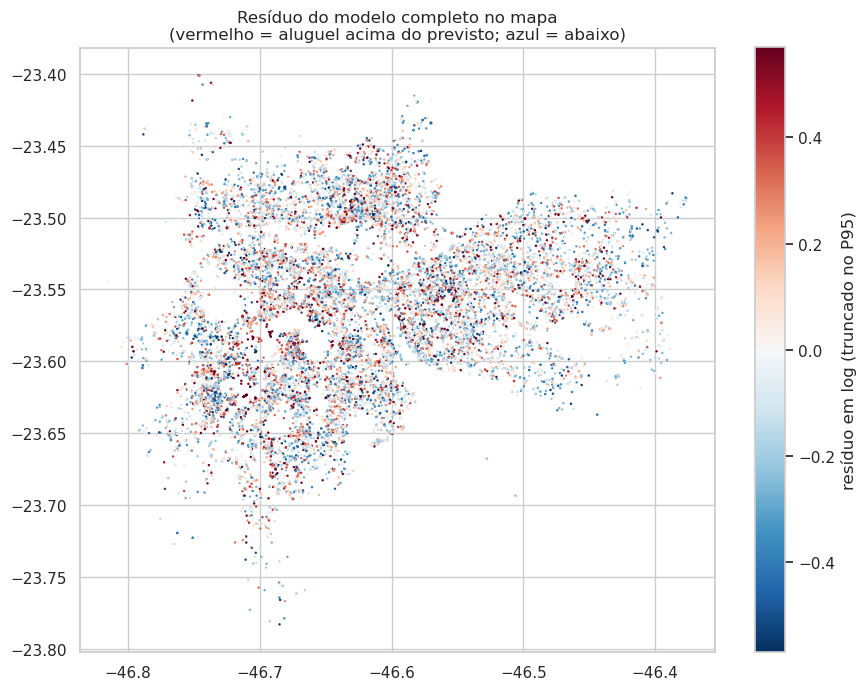

In [22]:
df["residuo"] = m_completo.resid
lim = df["residuo"].abs().quantile(0.95)
fig, ax = plt.subplots(figsize=(9, 9))
sc = ax.scatter(df["lon"], df["lat"], c=df["residuo"].clip(-lim, lim), cmap="RdBu_r", vmin=-lim, vmax=lim,
                s=3, linewidths=0)
ax.set_aspect(1 / np.cos(np.radians(-23.55)))
ax.set_title("Resíduo do modelo completo no mapa\n(vermelho = aluguel acima do previsto; azul = abaixo)")
fig.colorbar(sc, ax=ax, shrink=0.7, label="resíduo em log (truncado no P95)")
plt.tight_layout()
plt.show()
df = df.drop(columns="residuo")

## 12. Quadro-resumo das hipóteses

In [23]:
quadro = pd.DataFrame(resumo)
quadro["p"] = quadro["p"].map(lambda p: "—" if pd.isna(p) else ("< 0,001" if p < 0.001 else f"{p:.3f}"))
with pd.option_context("display.max_colwidth", 80):
    display(quadro.set_index("hipótese"))

,pergunta,teste,estatística,p,efeito,conclusão
hipótese,,,,,,
H7,Variáveis de planta são colineares?,VIF,VIF máx = 5.1,—,bathrooms = 5.1,Colinearidade moderada
H1,Aluguel cresce menos que proporcionalmente à área?,"OLS log-log + FE região, t-test β=1",β = 0.64 [0.61; 0.67],"< 0,001",+10% área → +6.3% aluguel,Rejeita H0: elasticidade < 1
H4,Tipo muda o aluguel na mesma área e região?,"OLS + FE região, Wald conjunto",χ² = 302.4,"< 0,001",Casa -22%; CasaCondominio -8%; Studio +8%,Rejeita H0: tipo tem efeito próprio
H2,R$/m² difere entre regiões?,Kruskal-Wallis,"H = 8,532","< 0,001",ε² = 0.42 (grande),Rejeita H0: regiões diferem
H9,Efeito da distância ao centro é não linear?,F aninhado linear × spline,F = 226.0,"< 0,001",pico em ~4.1 km; ΔAIC = 879,Rejeita H0: não linear
H3,Mobiliado aumenta o aluguel (mesma planta e região)?,OLS modelo completo + FE região (cluster),+14.3% [+12.6%; +15.9%],"< 0,001",ingênuo +42% → controlado +14.3%,Efeito controlado relevante
H5,Aceitar pet altera o aluguel?,OLS modelo completo + FE região (cluster),+1.0% [-0.1%; +2.2%],0.066,ingênuo +20% → controlado +1.0%,Sem efeito controlado
H6,Piscina mantém efeito após controles?,OLS modelo completo + FE região (cluster),+7.9% [+6.2%; +9.5%],"< 0,001",ingênuo +41% → controlado +7.9%,Efeito controlado relevante
H8,Perto de metrô/trem aumenta o aluguel?,OLS modelo completo + FE região (cluster),+8.3% [+4.8%; +11.9%],"< 0,001",ingênuo +11% → controlado +8.3%,Efeito controlado relevante


In [24]:
# Salva o quadro e os coeficientes do modelo de referência
OUT_DIR = ROOT / "results/inference"
OUT_DIR.mkdir(parents=True, exist_ok=True)
quadro.to_csv(OUT_DIR / "aluguel_hipoteses.csv", index=False)
coef.to_csv(OUT_DIR / "aluguel_ols_coeficientes.csv")
print(f"Salvo em {OUT_DIR.relative_to(ROOT)}/")

Salvo em results/inference/


## 13. Conclusões e implicações para o 03/04

### O que os testes confirmam

| # | Resultado | Tamanho do efeito |
|---|---|---|
| **H2** | Localização é o fator dominante: o R$/m² difere fortemente entre regiões | ε² = 0,42 (grande); só 3 de 45 pares entre as 10 maiores regiões não diferem (Tatuapé, Mooca, Água Fria) |
| **H1** | O aluguel cresce **menos** que a área | β = 0,64 [0,61; 0,67]: +10% de área → +6,3% de aluguel. Studio tem a menor elasticidade (0,44) |
| **H9** | A distância ao centro **não é linear** | Pico em ~4 km da Sé; a spline reduz o AIC em 879. Um apartamento de 60 m² vale ~R$ 2.500 no marco zero, ~R$ 4.000 a 4 km e ~R$ 1.500 a 25 km |
| **H4** | O tipo tem efeito próprio na mesma área e região | Casa −22%, Casa em condomínio −8%, Studio +8% (controlando só área e região) |
| **H3** | Mobiliado encarece o aluguel mesmo controlando planta, região e outros itens | +14% [+13%; +16%] — bem abaixo dos +42% ingênuos |
| **H6** | Piscina mantém efeito, mas pequeno | +8% [+6%; +10%] — eram +41% ingênuos: a maior parte era "prédio novo em região cara" |
| **H8** | Estar perto de metrô/trem tem valor | +8% [+5%; +12%]; o efeito **aumenta** ao controlar a planta (imóveis perto do metrô são menores) |
| **H11** | Regiões caras concentram studios, mesmo excluindo os studios do cálculo do preço | ρ = 0,74; +10 R$/m² na região → +4,5 p.p. de studios, controlando a distância |
| **H10** | O efeito da mobília varia um pouco por tipo | De +12% (casa em condomínio) a +23% (studio); diferença significativa, mas modesta (p = 0,02) |

### O que os testes descartam
- **H5 — Aceitar pet:** ingênuo +20%, controlado +1,0% [−0,1%; +2,2%]. Sem efeito no preço. Pode ficar na UI como filtro, mas não precisa entrar no modelo.
- **Vista livre:** sem efeito controlado (−0,2%).
- **Studio "caro por natureza":** o prêmio de +8% do studio vira **−4%** no modelo completo. O R$/m² alto vem do tamanho pequeno, da localização e de vir mobiliado e com ar-condicionado — não do tipo em si.

### Diagnóstico do modelo econométrico de referência
- R² = 0,83 com planta, 9 atributos e efeito fixo de 134 regiões. O desvio do resíduo é 0,28 em log, ou seja, **±32% no aluguel** para 1 desvio-padrão. Esse é o número que o modelo de ML precisa bater.
- Resíduos heterocedásticos (Breusch-Pagan rejeita) e com caudas pesadas → justificam erro robusto aqui e métricas robustas (MAE, mediana do erro percentual) no 04.
- **Sobra sinal espacial:** a correlação do resíduo com a média dos 10 vizinhos cai de 0,54 para 0,33 com o efeito fixo de região, mas não some. A região é grande demais para capturar o micro-local.
- Multicolinearidade moderada (VIF máx. 5,1 em banheiros): não atrapalha árvores; em modelos lineares, tirar `bedrooms`.

### Implicações para o 03 (features)
1. **Localização fina:** lat/lon brutas, **target encoding de vizinhança** (média de `log(rent/m²)` dos k vizinhos, calculada dentro do fold) e distância a polos de valor (Faria Lima, Paulista, Berrini). É onde está o maior ganho, pelo sinal espacial residual.
2. **Distância ao centro como não linear:** spline ou deixar para a árvore; nunca linear num modelo linear.
3. **POIs:** testar a distância real a estações de metrô (OSM) contra a flag `inst_perto_de_metro_ou_trem`, que já mostrou +8%.
4. **Manter:** `log_area`, tipo, banheiros, suítes, vagas, mobiliado, ar-condicionado, piscina, academia, varanda. **Descartar ou baixa prioridade:** pet, vista livre.
5. **Interações** tipo × área e tipo × mobiliado: favorecem modelos de árvore (LightGBM, CatBoost).

### Implicações para o 04 (modelagem)
- **Baselines a vencer:** (a) mediana de R$/m² da região × área; (b) este OLS com efeito fixo de região (±32%).
- **Validação espacial obrigatória:** com resíduo autocorrelado, o KFold aleatório vai superestimar a performance. Usar `GroupKFold` por cluster espacial (ex.: KMeans em lat/lon) e reportar as duas versões.
- **Decisão pendente sobre `iptuPlusCondominium`:** não entrou aqui. No 04, comparar o modelo com e sem ele, porque o usuário teria de informar o valor na UI.